In [32]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange, repeat
from matplotlib import pyplot as plt

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp
from torch.autograd import grad, Variable

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection, input_embedding
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.uoro import UOROModel
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.my_uoro import UORO

%load_ext autoreload
%autoreload 2
device = 'cuda:0'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [30]:
import numpy as np


def one_hot_encode(value, n_class):
    vec = np.zeros([n_class])
    vec[value] = 1
    return vec


def one_hot_decode(encoded_seq):
    return [np.argmax(vector) for vector in encoded_seq]


def get_an_bn_array(num_data, k, l):
    """
    modified from https://github.com/petered/uoro-demo
    """
    x = np.zeros([num_data], dtype=int)

    i = 0
    while i < num_data:
        n = np.random.randint(low=k, high=l+1)
        x[i:i+n] = 1
        x[i+n+1: i+2*n+1] = 2
        i += 2*n + 2
    return x


def generate_anbn_data(num_data, k=1, l=4, num_class=3):
    X_arr = get_an_bn_array(num_data+1, k, l)
    X = np.zeros([1, num_data, num_class])
    Y = np.zeros([1, num_data, num_class])
    for i in range(num_data):
        X[0, i] = one_hot_encode(X_arr[i], num_class)
        Y[0, i] = one_hot_encode(X_arr[i+1], num_class)
    return X, Y


X, Y = generate_anbn_data(10000, k=1, l=4, num_class=3)
X = torch.from_numpy(X).float().to(device)
Y = torch.from_numpy(np.argmax(Y, axis=2)).long().to(device)

In [153]:
loss_all=[]
l = []
loss_acc=0
input_size=3
hidden_size=10
output_size=3
old_s = torch.zeros(size=[1, 1, hidden_size], requires_grad=True, device=device)
criterion=torch.nn.CrossEntropyLoss()
model=SimpleRNN(3,10,3).to(device)
uoro_grad = UORO(model)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
# UORO
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)

        y, new_s = model(x_t, old_s)
        loss=criterion(y[0], y_t)
        uoro_grad.step(model, x_t, new_s, old_s, loss)
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss.item())
        loss_acc += loss.item()
        if iter_id%100 == 0:
            print(loss_acc)
            loss_acc=0

In [ ]:
# BPTT
loss=torch.tensor(0.0, device=device)
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)

        y, new_s = model(x_t, old_s)
        loss+=criterion(y.squeeze(0), y_t)
        # uoro_grad.step(model, x_t, new_s, old_s, loss)
        if iter_id % 5 == 0:
            optimizer.zero_grad()
            loss.backward()
            old_s = new_s.detach().clone().requires_grad_(True)
            optimizer.step()
            loss_all.append(loss.item()/5)
            loss_acc += loss.item()
            loss=torch.tensor(0.0, device=device)
        else:
            old_s = new_s.clone() #.detach().clone()  #.detach().clone().requires_grad_(True)
        
        if iter_id%100 == 0:
            print(loss_acc)
            loss_acc=0

In [39]:
from memoryPerceiver.memory_perceiver.main.configuration import cf
loss_all = []
loss_acc=0
criterion=torch.nn.CrossEntropyLoss()
cf.body_outputs['critic']=3 # agent.py -> values = rearrange(output['critic'], 'b () d -> b d')
cf.shared=True 
cf.dim_observations=3
cf.num_envs=1
cf.depth=1
cf.query_dim=4
cf.nb_latents=2
cf.nb_latents_mem=2
cf.latent_dim_head=2
model=create_agent(cf, device)
old_s = create_memories(model.actor, cf.num_envs, device=device)
mem_dim = old_s.shape
old_s = rearrange(old_s, 'b d l h -> (b d l h)')
uoro_grad = UORO(model)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
model.train()
dummy0=torch.zeros(cf.num_envs, 1, cf.dim_actions, device=device)
states = {}

In [34]:
model

ActorCriticPerceiver(
  (actor): PerceiverIO(
    (out_embedding): ModuleDict(
      (observation_0): Linear(in_features=1, out_features=4, bias=True)
      (observation_1): Linear(in_features=1, out_features=4, bias=True)
      (observation_2): Linear(in_features=1, out_features=4, bias=True)
      (observation_3): Linear(in_features=1, out_features=4, bias=True)
    )
    (out_cross_attn): PreNormContext(
      (fn): Attention(
        (to_q): Linear(in_features=4, out_features=2, bias=False)
        (to_kv): Linear(in_features=4, out_features=4, bias=False)
        (to_out): Linear(in_features=2, out_features=4, bias=True)
      )
    )
    (out_cross_ff): PreNormContext(
      (fn): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=4, out_features=16, bias=True)
          (1): ReLU()
          (2): Linear(in_features=16, out_features=4, bias=True)
        )
      )
    )
    (out_attn_layers): ModuleList(
      (0): PreNormContext(
        (fn): Attention(
 

In [40]:
print(uoro_grad.theta_tilda.shape)

torch.Size([1325])


In [35]:
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)
        y_t = Y[:   , iter_id:(iter_id+1)].reshape([1]).to(device)
        y_t = repeat(y_t, '1 -> b', b=cf.num_envs)
        _, y, _, new_s = model(states, old_s, old_actions=dummy0, flattened_mem=mem_dim)
        # y = torch.nn.functional.softmax(y)
        loss=criterion(y, y_t)
        uoro_grad.step(model, states, new_s, old_s, loss, old_actions=dummy0, flattened_mem=mem_dim)
        # loss.backward()
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss.item())
        loss_acc += loss.item()
        if iter_id%100 == 0:
            print(loss_acc)
            loss_acc=0

1.55459463596344
120.66335555911064
115.15158849954605
111.23084378242493
109.36607331037521
108.60013443231583
107.71702110767365
107.08492487668991
103.39804399013519
100.82699853181839
99.4358018040657
96.16894316673279
99.90976059436798
99.93060553073883
99.93998897075653
100.29311668872833
98.0012059211731
96.99000823497772
97.74722349643707
96.66484653949738
99.43090504407883
92.50539922714233
97.98253458738327
99.40606141090393
98.87522631883621
97.30773055553436
91.54893952608109
101.46001929044724
98.76167100667953
99.95639818906784
98.90388023853302
98.94123578071594
99.14489269256592
97.01959586143494
98.66184043884277
98.52621656656265
96.25259053707123
99.44897812604904
93.82088494300842
100.78421920537949
99.5857350230217
98.9223582148552
96.34432339668274
96.03033882379532
91.76395899057388
101.39428853988647
98.28967064619064
97.68431454896927
98.79592174291611
98.95760279893875
96.93892359733582
95.81465590000153
95.22553074359894
95.26278465986252
98.57523983716965
98

KeyboardInterrupt: 

In [40]:
# BPTT
loss=torch.tensor(0.0, device=device)
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)
        y_t = repeat(y_t, '1 -> b', b=cf.num_envs)

        _, y, _, new_s = model(states, old_s, old_actions=dummy0, flattened_mem=mem_dim)
        loss+=criterion(y, y_t)
        # uoro_grad.step(model, x_t, new_s, old_s, loss)
        if iter_id % 5 == 0:
            optimizer.zero_grad()
            loss.backward()
            old_s = new_s.detach().clone().requires_grad_(True)
            optimizer.step()
            loss_all.append(loss.item()/5)
            loss_acc += loss.item()
            loss=torch.tensor(0.0, device=device)
        else:
            old_s = new_s.clone() #.detach().clone()  #.detach().clone().requires_grad_(True)
        
        if iter_id%100 == 0:
            print(loss_acc)
            loss_acc=0

1.618308186531067


120.08530616760254
116.09650421142578
117.24393510818481
118.75713777542114
118.8847165107727
120.18394899368286
118.58818531036377
115.08834552764893
117.20773887634277
117.35904884338379
115.64699506759644
116.32492113113403
118.73646879196167
117.11697626113892
117.45859432220459
114.33498954772949
115.618088722229
113.76434087753296
114.60460472106934
115.2216854095459
111.83673095703125
114.88606595993042
114.61867904663086
113.82730293273926
114.26525735855103
110.97176218032837
113.79642391204834
113.50470352172852
114.33975028991699
113.0805983543396
112.91193199157715
112.75167846679688
112.11549186706543
112.39599370956421
112.24137735366821
111.7754020690918
111.95150804519653
110.94129800796509
112.38665962219238
111.87189245223999
111.4949722290039
111.1506576538086
110.8238205909729
111.04351615905762
111.83075141906738
111.00503730773926
110.55713844299316
110.53522777557373
110.90014886856079
110.59242630004883
110.69908428192139
110.65286302566528
110.4227294921875
110

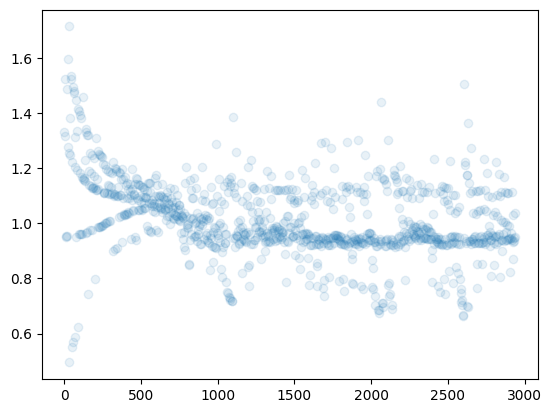

In [37]:
# < 0.68 and close to 0.23 to beat no-memory 
# plt.plot(loss_all)
h=3
#plt.plot([sum(loss_all[i: i+h])/h for i in range(0,int(len(loss_all)/h),h)], alpha=0.5)
plt.scatter(x=list(range(0,int(len(loss_all)/h),h)) , y=[sum(loss_all[i: i+h])/h for i in range(0,int(len(loss_all)/h),h)], alpha=0.1)
plt.show()

In [88]:
torch.tensor(loss_all)[:5000].mean()

tensor(4.0921)